# CostRouter — Pareto Report

Short report for SRS §2.6: does difficulty- and budget-aware routing between a
cheap and an expensive model buy a better cost/accuracy trade-off than using
either model alone?

**Setup.** One mixed task set of real benchmark items — TriviaQA (`rc.nocontext`
validation, the "easy" set) and GSM8K (test, the "hard" set), sampled with a
fixed seed and shuffled together, as an agent would see easy and hard steps
interleaved. Every condition runs the same tasks through the same `RouterNode`:

* `always_cheap` / `always_expensive` — baselines (no retries).
* `router t=…` — the default threshold policy at 5 thresholds (REQ-BENCH-4).
  Thresholds sit at the 10/30/50/70/90th percentiles of the estimator's
  prompt-only score (length + reasoning cues), computed from the prompts alone
  — no model calls, no gold labels.
* `router … capped` — the lowest threshold with half the `always_expensive`
  spend as its budget, to exercise budget-forced routing (SRS §5.2).

The router's validator requires a `Final answer:` line; a cheap reply without one
is retry-escalated to the expensive model and counts as a failure in the
per-dataset history. Grading is exact match on the `Final answer:` line
(normalised alias match for TriviaQA, numeric match for GSM8K).

Responses are cached per (model, prompt) at temperature 0, so every condition
sees identical answers and differences between runs come from routing alone.
Costs are each call's real token usage × the provider's list price.


In [1]:
import json, sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().resolve()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
conn = sqlite3.connect(f"{(ROOT / 'costrouter.db').as_uri()}?mode=ro", uri=True)
summary = json.loads((ROOT / "reports" / "summary.json").read_text(encoding="utf-8"))
meta = summary["meta"]
runs = pd.DataFrame(summary["runs"])
pd.set_option("display.width", 160)
print(f"Provider: {meta['provider']}")
print(f"Cheap:     {meta['cheap_model']}  (USD/1M tokens in, out: {meta['rates_usd_per_1m']['cheap']})")
print(f"Expensive: {meta['expensive_model']}  (USD/1M tokens in, out: {meta['rates_usd_per_1m']['expensive']})")
print(f"Tasks: {meta['tasks']}  ({meta['n_per_dataset']} TriviaQA + {meta['n_per_dataset']} GSM8K), "
      f"temperature {meta['temperature']}, max_tokens {meta['max_tokens']}, seed {meta['seed']}")


Provider: groq
Cheap:     openai/gpt-oss-20b  (USD/1M tokens in, out: [0.075, 0.3])
Expensive: openai/gpt-oss-120b  (USD/1M tokens in, out: [0.15, 0.6])
Tasks: 100  (50 TriviaQA + 50 GSM8K), temperature 0.0, max_tokens 1024, seed 42


## Results by condition

`cost_vs_expensive` is each run's spend relative to `always_expensive`.

In [2]:
table = runs.assign(
    triviaqa=runs.accuracy_by_dataset.map(lambda d: d.get("triviaqa")),
    gsm8k=runs.accuracy_by_dataset.map(lambda d: d.get("gsm8k")),
)[["label", "accuracy", "triviaqa", "gsm8k", "total_cost", "expensive_share",
   "retries", "budget_forced", "errors"]]
base_cost = runs.loc[runs.condition == "always_expensive", "total_cost"].iloc[0]
table["cost_vs_expensive"] = table.total_cost / base_cost
table.style.format({"accuracy": "{:.1%}", "triviaqa": "{:.1%}", "gsm8k": "{:.1%}",
                    "total_cost": "${:.5f}", "expensive_share": "{:.0%}",
                    "cost_vs_expensive": "{:.0%}"}).hide(axis="index")


label,accuracy,triviaqa,gsm8k,total_cost,expensive_share,retries,budget_forced,errors,cost_vs_expensive
always_cheap,84.0%,72.0%,96.0%,$0.00943,0%,0,0,7,70%
always_expensive,89.0%,82.0%,96.0%,$0.01343,100%,0,0,0,100%
router t=0.0262,88.0%,80.0%,96.0%,$0.01368,98%,1,0,0,102%
router t=0.0289,88.0%,80.0%,96.0%,$0.01365,97%,1,0,0,102%
router t=0.039,88.0%,80.0%,96.0%,$0.01283,80%,1,0,0,96%
router t=0.0532,87.0%,78.0%,96.0%,$0.01314,71%,3,0,0,98%
router t=0.065,87.0%,78.0%,96.0%,$0.01244,53%,4,0,0,93%
router t=0.0262 capped $0.006716 soft,84.0%,72.0%,96.0%,$0.01127,46%,1,50,4,84%
router t=0.0262 capped $0.006716 hard,40.0%,36.0%,44.0%,$0.00642,94%,1,1,53,48%


## Where the two models differ

The headroom available to *any* router is set by where the cheap model loses accuracy.

In [3]:
# Reference points built from the baselines' graded answers (no extra calls):
# - per-dataset oracle: TriviaQA -> expensive, GSM8K -> cheap (picked with hindsight);
# - the dotted "mix" line in the chart: randomly sending a fraction p of tasks to the
#   expensive model.
tr = pd.read_sql("SELECT run_id, task_id, dataset, correct, total_cost_usd FROM task_results", conn)
cheap_tr = tr[tr.run_id == runs.loc[runs.condition == "always_cheap", "run_id"].iloc[0]].set_index("task_id")
exp_tr = tr[tr.run_id == runs.loc[runs.condition == "always_expensive", "run_id"].iloc[0]].set_index("task_id")
pick = pd.concat([exp_tr[exp_tr.dataset == "triviaqa"], cheap_tr[cheap_tr.dataset == "gsm8k"]])
oracle = {"accuracy": pick.correct.mean(), "total_cost": pick.total_cost_usd.sum()}
print(f"Per-dataset oracle: accuracy {oracle['accuracy']:.1%} at ${oracle['total_cost']:.5f} "
      f"({oracle['total_cost'] / base_cost:.0%} of always_expensive)")
print("Per-dataset accuracy and spend, cheap vs expensive:")
pd.DataFrame({
    "cheap_acc": cheap_tr.groupby("dataset").correct.mean(),
    "expensive_acc": exp_tr.groupby("dataset").correct.mean(),
    "cheap_cost": cheap_tr.groupby("dataset").total_cost_usd.sum(),
    "expensive_cost": exp_tr.groupby("dataset").total_cost_usd.sum(),
}).style.format({"cheap_acc": "{:.0%}", "expensive_acc": "{:.0%}",
                 "cheap_cost": "${:.5f}", "expensive_cost": "${:.5f}"})


Per-dataset oracle: accuracy 89.0% at $0.00984 (73% of always_expensive)
Per-dataset accuracy and spend, cheap vs expensive:


,cheap_acc,expensive_acc,cheap_cost,expensive_cost
dataset,,,,
gsm8k,96%,96%,$0.00493,$0.00853
triviaqa,72%,82%,$0.00450,$0.00490


## Pareto view (REQ-BENCH-5)

Cost on x, accuracy on y. The dashed line joins the router sweep, the dotted line is a random mix of the two baselines, and the vertical line marks the budget cap of the two capped runs.

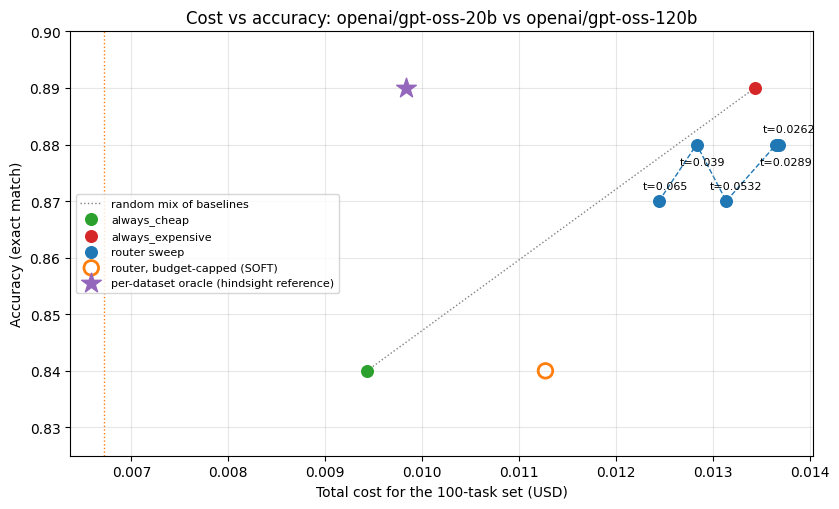

In [4]:
colors = {"always_cheap": "#2ca02c", "always_expensive": "#d62728", "router": "#1f77b4"}
is_cap = runs.run_id.str.contains("budgetcap")
fig, ax = plt.subplots(figsize=(8.5, 5.2))
base = runs[runs.condition != "router"].sort_values("total_cost")
ax.plot(base.total_cost, base.accuracy, ":", color="grey", lw=1, label="random mix of baselines")
sweep = runs[(runs.condition == "router") & ~is_cap].sort_values("total_cost")
ax.plot(sweep.total_cost, sweep.accuracy, "--", color=colors["router"], lw=1, zorder=1)
for cond, group in runs[~is_cap].groupby("condition"):
    ax.scatter(group.total_cost, group.accuracy, s=70, color=colors[cond],
               label=cond if cond != "router" else "router sweep", zorder=2)
# The HARD_STOP run refuses steps once the cap is hit (see the budget section),
# so its accuracy isn't comparable on this chart.
soft = runs[is_cap & ~runs.run_id.str.contains("hardstop")]
ax.scatter(soft.total_cost, soft.accuracy, s=110, facecolors="none", edgecolors="#ff7f0e",
           linewidths=2, zorder=3, label="router, budget-capped (SOFT)")
ax.scatter(oracle["total_cost"], oracle["accuracy"], marker="*", s=220, color="#9467bd", zorder=3,
           label="per-dataset oracle (hindsight reference)")
for k, (_, r) in enumerate(sweep.iterrows()):
    ax.annotate(f"t={r.threshold:g}", (r.total_cost, r.accuracy), textcoords="offset points",
                xytext=(-12, 9 if k % 2 == 0 else -15), fontsize=8)
ax.axvline(runs.loc[is_cap, "budget_usd"].iloc[0], color="#ff7f0e", ls=":", lw=1)
ax.set_xlabel("Total cost for the 100-task set (USD)")
ax.set_ylabel("Accuracy (exact match)")
ax.set_title(f"Cost vs accuracy: {meta['cheap_model']} vs {meta['expensive_model']}")
ax.grid(alpha=0.3)
lo, hi = runs.loc[~runs.run_id.str.contains("hardstop"), "accuracy"].agg(["min", "max"])
ax.set_ylim(lo - 0.015, max(hi, oracle["accuracy"]) + 0.01)
ax.legend(loc="center left", fontsize=8)
fig.tight_layout()
(ROOT / "docs").mkdir(exist_ok=True)
fig.savefig(ROOT / "docs" / "pareto.png", dpi=150)
plt.show()


## How the router spent its budget

Where the expensive calls went, by dataset, and how many came from retry-escalation.

In [5]:
dec = pd.read_sql(
    "SELECT d.run_id, d.task_id, d.model_chosen, d.retried, d.budget_forced, d.difficulty_score "
    "FROM routing_decisions d JOIN runs r USING (run_id) WHERE r.condition = 'router'", conn)
dec["dataset"] = dec.task_id.str.rsplit("-", n=1).str[0]
dec["expensive"] = dec.model_chosen.eq("expensive")
labels = runs.set_index("run_id").label
share = (dec.groupby(["run_id", "dataset"]).expensive.mean().unstack()
            .rename(index=labels).sort_values("gsm8k"))
retry = dec.groupby(["run_id", "dataset"]).retried.sum().unstack().rename(index=labels)
print("Share of steps answered by the expensive model, per dataset:")
display(share.style.format("{:.0%}"))
print("Retry-escalations (cheap reply had no 'Final answer:' line):")
display(retry.loc[share.index])


Share of steps answered by the expensive model, per dataset:


dataset,gsm8k,triviaqa
run_id,,
router t=0.0262 capped $0.006716 soft,44%,48%
router t=0.065,56%,50%
router t=0.0532,82%,60%
router t=0.039,94%,66%
router t=0.0262 capped $0.006716 hard,96%,92%
router t=0.0262,100%,96%
router t=0.0289,100%,94%


Retry-escalations (cheap reply had no 'Final answer:' line):


dataset,gsm8k,triviaqa
run_id,,
router t=0.0262 capped $0.006716 soft,0,1
router t=0.065,1,3
router t=0.0532,1,2
router t=0.039,0,1
router t=0.0262 capped $0.006716 hard,0,1
router t=0.0262,0,1
router t=0.0289,0,1


## Budget-capped runs (SRS §5.2: degradation is visible, not hidden)

Same router, budget capped at half the `always_expensive` spend, in each `BudgetMode`.

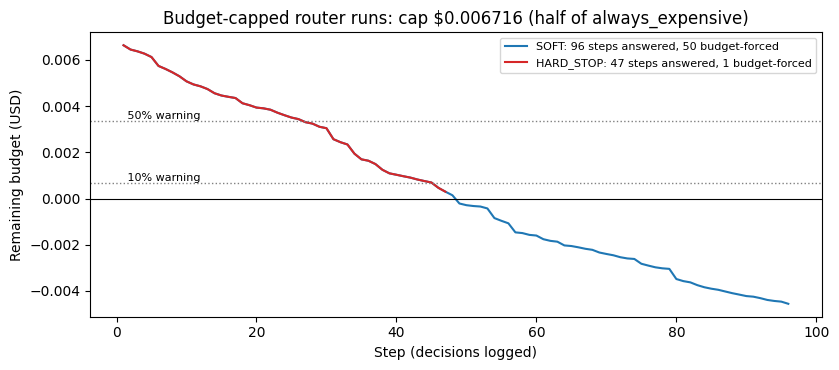

SOFT      spent $0.01127 of $0.006716, accuracy 84%, 50 budget-forced decisions, 4 steps not answered
HARD_STOP spent $0.00642 of $0.006716, accuracy 40%, 1 budget-forced decisions, 53 steps not answered


,run_id,threshold_pct,remaining_budget
0,router-t0.0262-budgetcap-mixed,0.5,0.003307
1,router-t0.0262-budgetcap-mixed,0.1,0.000464
2,router-t0.0262-budgetcap-hardstop-mixed,0.5,0.003307
3,router-t0.0262-budgetcap-hardstop-mixed,0.1,0.000464


In [6]:
fig, ax = plt.subplots(figsize=(8.5, 3.8))
for _, r in runs[is_cap].iterrows():
    hard = "hardstop" in r.run_id
    traj = pd.read_sql("SELECT budget_remaining_after, budget_forced FROM routing_decisions "
                       "WHERE run_id = ? ORDER BY id", conn, params=(r.run_id,))
    ax.plot(range(1, len(traj) + 1), traj.budget_remaining_after,
            color="#d62728" if hard else "#1f77b4",
            label=f"{'HARD_STOP' if hard else 'SOFT'}: {len(traj)} steps answered, "
                  f"{int(traj.budget_forced.sum())} budget-forced")
ax.axhline(0, color="black", lw=0.8)
for pct in (0.5, 0.1):
    ax.axhline(pct * r.budget_usd, color="grey", ls=":", lw=1)
    ax.text(1, pct * r.budget_usd, f" {pct:.0%} warning", va="bottom", fontsize=8)
ax.set_xlabel("Step (decisions logged)")
ax.set_ylabel("Remaining budget (USD)")
ax.set_title(f"Budget-capped router runs: cap ${r.budget_usd:g} (half of always_expensive)")
ax.legend(loc="upper right", fontsize=8)
fig.tight_layout()
plt.show()
for _, r in runs[is_cap].iterrows():
    mode = "HARD_STOP" if "hardstop" in r.run_id else "SOFT"
    print(f"{mode:<9} spent ${r.total_cost:.5f} of ${r.budget_usd:g}, accuracy {r.accuracy:.0%}, "
          f"{r.budget_forced} budget-forced decisions, {r.errors} steps not answered")
events = pd.read_sql("SELECT r.run_id, e.threshold_pct, e.remaining_budget FROM budget_events e "
                     "JOIN runs r USING (run_id) ORDER BY e.id", conn)
events


## Grading spot-check (Phase 6)

Every baseline answer is in `reports/spot_check.csv` (graded span vs gold aliases). A random sample:

In [7]:
spot = pd.read_csv(ROOT / "reports" / "spot_check.csv")
print(spot.groupby(["run", "dataset"]).correct.agg(["mean", "count"]))
spot.sample(12, random_state=0)


                           mean  count
run              dataset              
always_cheap     gsm8k     0.96     50
                 triviaqa  0.72     50
always_expensive gsm8k     0.96     50
                 triviaqa  0.82     50


,run,task_id,dataset,model,correct,graded_span,gold
18,always_cheap,gsm8k-26,gsm8k,cheap,1,21**,21
170,always_expensive,triviaqa-0,triviaqa,expensive,1,St. Basil's Cathedral,St. Basil's | Cathedral of the Intercession | ...
107,always_expensive,gsm8k-20,gsm8k,expensive,1,11050**,11050
98,always_cheap,triviaqa-14,triviaqa,cheap,1,E,E | ⒠ | Ｅ | 🄔 | 🅴
177,always_expensive,gsm8k-21,gsm8k,expensive,1,45**,45
182,always_expensive,triviaqa-27,triviaqa,expensive,1,Crimson Tide,'CRIMSON TIDE' | Crimson Tide | The Crimson Ti...
5,always_cheap,gsm8k-0,gsm8k,cheap,1,18**,18
146,always_expensive,gsm8k-11,gsm8k,expensive,1,145**.,145
12,always_cheap,gsm8k-5,gsm8k,cheap,1,8000**,8000
152,always_expensive,triviaqa-2,triviaqa,expensive,1,yellow,Yellow | Yellowest | Whiteyellow | Yelow | Yel...


## Findings

**1. The two models differ only on TriviaQA.** `gpt-oss-20b` and `gpt-oss-120b` both score
96% on GSM8K; the whole 5-point gap (84% vs 89% overall) is on TriviaQA, 72% vs 82%. The
expensive model costs 2× per token, but because the small model spends more hidden reasoning
tokens, `always_expensive` costs only 1.42× `always_cheap` ($0.0134 vs $0.0094 for 100 tasks).
On TriviaQA the cheap model saves almost nothing ($0.0045 vs $0.0049).

**2. The v1 heuristic router lands on, not above, the random-mix line.** The 5-threshold sweep
gives 5 distinct points (REQ-BENCH-4): 87–88% accuracy at 93–102% of the `always_expensive`
cost, with 53–98% of steps on the expensive model. That is about what randomly mixing the two
models would give. The reason is visible in the routing table: the length + reasoning-cue score
says the long GSM8K problems are hard, so they go to the expensive model, where nothing is
gained. The failure-history signal pulls the other way — truncated cheap TriviaQA replies fail
validation, which raises TriviaQA's history score (50% of TriviaQA went expensive at the
highest threshold, against ~0% predicted from the prompts alone) — but not enough to fix it.

**3. The headroom is real.** Routing by dataset with hindsight (TriviaQA → expensive,
GSM8K → cheap) would match `always_expensive`'s 89% at **73% of its cost**. A step-type-aware
policy, or the learned estimator that REQ-DIFF-2 leaves room for, is the next step. The lesson
for v1: prompt length is a poor difficulty proxy when the cheap model is itself a reasoning model.

**4. Retry-escalate earns its keep.** 7 of the 100 cheap replies were empty: `gpt-oss-20b`
spent the entire 1,024-token cap on hidden reasoning (6 of the 7 were TriviaQA). The router's
`Final answer:` validator caught every one that reached the cheap model and re-ran it on the
expensive model (1–4 escalations per run), which is why every router point beats
`always_cheap` on accuracy. Both attempts are charged to the ledger, which is why the two
lowest-threshold points cost slightly *more* than `always_expensive`.

**5. Budget modes behave as specified, and the difference matters.** With the budget capped at
half the `always_expensive` spend ($0.0067):

* **SOFT** downgraded 50 decisions to the cheap model and fired both warnings (50%, 10%), but
  kept answering after the cap — final spend $0.0113, 168% of the cap, at 84% accuracy. With a
  cheap model only ~1.4× cheaper, "cheap-only after exhaustion" is *not* a spending cap.
* **HARD_STOP** stayed under the cap ($0.0064) by refusing the remaining 53 steps.

Use HARD_STOP when the budget is a hard limit; SOFT when finishing the task matters more.

**6. Grading spot-check (Phase 6).** All 27 answers graded wrong and all 12 graded right
without an exact alias match were checked by hand; the graders made no mistakes. Two
dataset-label issues were found and left as-is (official labels are used):
GSM8K item 49's gold answer is 2280, but the correct total is 750 + 430 + 700 + 300 = 2180 —
both models answered 2180 and are marked wrong; and TriviaQA item 38's gold answer is Lady
Bracknell, but its alias list (drawn from a page about the play's characters) also contains
"Jack Worthing" and "Algernon Moncrieff", so the expensive model's "Jack Worthing" counts as right.

**Caveats.** 100 tasks gives a standard error of about ±3 points on accuracy, so 1-point
differences between router thresholds are noise; the cost differences are exact. One model
pair, one provider, list prices. Every condition replays the same cached response per
(model, prompt), so routing is the only variable — and the per-call latencies in the database
are not meaningful. `python -m benchmark.run --offline --fresh` rebuilds these exact numbers
from the committed cache.
